# LogBERT HDFS V2 — tuning contrôlé du masquage

V2 part de la baseline officielle V1 et ne change qu’une famille d’hyperparamètres : le ratio de masquage `m`. Le modèle, le parser, le split, les données et la méthode d’inférence restent les mêmes. Les choix de `m`, `g` et `r` sont effectués uniquement sur validation. Le test complet est évalué après gel du meilleur réglage.

Le point de départ V1 est `m=0.65`, `g=6`, `r=0`. V2 compare `m ∈ {0.50, 0.65, 0.75}`; l’inférence utilise toujours le même `m` que l’entraînement correspondant.


## 1. Dépendances et dépôt officiel

La première cellule met Pandas à une version compatible sans remplacer NumPy, déjà fourni par Kaggle. NumPy 2.0.2 et 2.2.6 sont tous deux acceptés. Si l’import Pandas échoue encore avec une erreur ABI, redémarrer le kernel après l’installation, puis relancer depuis le début.

Pour Colab via VS Code, fournir les chemins par variables d’environnement `HDFS_LOG_PATH` et `HDFS_LABEL_PATH`, ou placer les deux fichiers dans le même dossier visible depuis `/content` ou le dossier de travail. `LOGBERT_WORK_DIR` permet de choisir le dossier des checkpoints et résultats.


In [ ]:
# Garder la version Torch fournie par Kaggle; installer seulement les dépendances de parsing/évaluation.
%pip install -q --force-reinstall --no-deps pandas==2.2.3
%pip install -q --no-deps regex==2023.12.25
print('Dépendances installées. Si NumPy/Pandas étaient déjà importés dans ce kernel, redémarrer la session Kaggle avant de poursuivre.')

import os, sys, json, ast, random, shutil, subprocess, importlib.util
from pathlib import Path
import numpy as np
if int(np.__version__.split(".")[0]) < 2:
    raise RuntimeError(f"NumPy {np.__version__} est chargé, mais NumPy 2.x est requis avec le Pandas de ce notebook. Mettre à jour NumPy/Pandas ensemble puis redémarrer le kernel.")
print("Versions NumPy/Pandas attendues : NumPy 2.x; runtime NumPy", np.__version__)
import pandas as pd
import torch
REQUIRE_GPU = True
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError("GPU non détecté. Dans Kaggle, ouvrir Settings > Accelerator, choisir un GPU (T4/P100), puis redémarrer la session et relancer le notebook.")
if torch.cuda.is_available():
    print("GPU actif :", torch.cuda.get_device_name(0))
    print("VRAM (GiB) :", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("GPU désactivé; l'exécution CPU est bloquée par REQUIRE_GPU=True.")
# Compatibility shims for the pinned 2023 reference code on current Kaggle runtimes.
for _name, _value in {"float": float, "int": int, "Inf": np.inf}.items():
    if not hasattr(np, _name):
        setattr(np, _name, _value)
if "torch._six" not in sys.modules:
    import types
    _torch_six = types.ModuleType("torch._six")
    _torch_six.string_classes = (str,)
    _torch_six.int_classes = (int,)
    sys.modules["torch._six"] = _torch_six
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

SEED = 1234
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

REPO_URL = "https://github.com/HelenGuohx/LogBERT.git"
REPO_COMMIT = "a845e612e919a6930065b69a40098eaaac26e1a3"
WORK_DIR = Path(os.environ.get("LOGBERT_WORK_DIR", str(Path.cwd() / ".logbert_hdfs_baseline"))).expanduser().resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
REPO_DIR = WORK_DIR / "LogBERT"
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", REPO_COMMIT], check=True)
sys.path.insert(0, str(REPO_DIR))
print("Repository:", REPO_DIR, "| commit:", subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip())
print("Torch:", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")

## 2. Trouver ou télécharger le HDFS complet

Le notebook cherche d’abord un jeu HDFS attaché. Si aucun fichier n’est visible, il télécharge automatiquement l’archive HDFS v1 officielle de LogHub (Zenodo, checksum MD5 vérifié) et le fichier de labels LogPai. Cela demande Internet activé dans Kaggle et environ 1,5 GB d’espace pour le log extrait. Aucun fallback HDFS_100k n’est utilisé.


In [ ]:
explicit_log = os.environ.get("HDFS_LOG_PATH")
explicit_labels = os.environ.get("HDFS_LABEL_PATH")
if explicit_log and explicit_labels:
    HDFS_LOG, LABEL_CSV = Path(explicit_log).expanduser().resolve(), Path(explicit_labels).expanduser().resolve()
else:
    roots = [Path("/kaggle/input"), Path("/content"), Path.cwd()]
    if os.environ.get("HDFS_INPUT_DIR"):
        roots.insert(0, Path(os.environ["HDFS_INPUT_DIR"]).expanduser())
    roots = list(dict.fromkeys(root.resolve() for root in roots if root.exists()))
    log_candidates = []
    label_candidates = []
    for root in roots:
        log_candidates.extend(p for p in root.rglob("*") if p.is_file() and p.name.lower() == "hdfs.log" and p.stat().st_size >= 100_000_000)
        label_candidates.extend(p for p in root.rglob("*") if p.is_file() and p.name.lower() == "anomaly_label.csv")
    log_candidates = list(dict.fromkeys(log_candidates))
    label_candidates = list(dict.fromkeys(label_candidates))
    pairs = [(log_path, label_path) for log_path in log_candidates for label_path in label_candidates]
    if pairs:
        def common_depth(pair):
            return len(Path(os.path.commonpath([str(pair[0]), str(pair[1])])).parts)
        best_depth = max(common_depth(pair) for pair in pairs)
        best_pairs = [pair for pair in pairs if common_depth(pair) == best_depth]
    else:
        best_pairs = []
    if len(best_pairs) == 0:
        # Official LogHub distribution: HDFS_v1 archive + LogPai HDFS labels.
        # The archive is ~187 MB compressed; the extracted HDFS.log is ~1.5 GB.
        import hashlib, urllib.request, zipfile
        download_dir = WORK_DIR / "downloaded_hdfs_v1"
        download_dir.mkdir(parents=True, exist_ok=True)
        archive_path = download_dir / "HDFS_v1.zip"
        hdfs_target = download_dir / "HDFS.log"
        labels_target = download_dir / "anomaly_label.csv"
        archive_url = "https://zenodo.org/records/8196385/files/HDFS_v1.zip?download=1"
        expected_md5 = "76a24b4d9a6164d543fb275f89773260"
        label_url = "https://raw.githubusercontent.com/logpai/loglizer/master/data/HDFS/anomaly_label.csv"

        if not hdfs_target.exists() or not labels_target.exists():
            print("Aucun HDFS complet attaché; téléchargement de la distribution officielle LogHub v1...")
            try:
                if not archive_path.exists() or archive_path.stat().st_size != 186645559:
                    digest = hashlib.md5()
                    request = urllib.request.urlopen(archive_url, timeout=120)
                    with archive_path.open("wb") as output:
                        while True:
                            chunk = request.read(1024 * 1024)
                            if not chunk:
                                break
                            output.write(chunk)
                            digest.update(chunk)
                    if digest.hexdigest() != expected_md5:
                        raise IOError(f"Checksum HDFS_v1.zip invalide: {digest.hexdigest()}")
                if not hdfs_target.exists():
                    with zipfile.ZipFile(archive_path) as archive:
                        member = next((name for name in archive.namelist() if Path(name).name == "HDFS.log"), None)
                        if member is None:
                            raise FileNotFoundError("HDFS.log absent de l'archive LogHub HDFS_v1.")
                        with archive.open(member) as source, hdfs_target.open("wb") as output:
                            while True:
                                chunk = source.read(1024 * 1024)
                                if not chunk:
                                    break
                                output.write(chunk)
                if not labels_target.exists():
                    urllib.request.urlretrieve(label_url, labels_target)
            except Exception as error:
                raise RuntimeError(
                    "Téléchargement automatique du HDFS complet impossible. Activer Internet dans Kaggle, "
                    "ou attacher HDFS.log et anomaly_label.csv via Add Input / définir HDFS_LOG_PATH et HDFS_LABEL_PATH."
                ) from error
        HDFS_LOG, LABEL_CSV = hdfs_target, labels_target
        print("HDFS officiel téléchargé:", HDFS_LOG, f"({HDFS_LOG.stat().st_size/1e9:.2f} GB)")
    elif len(best_pairs) > 1:
        raise FileNotFoundError(
            "Plusieurs couples HDFS candidats; définir explicitement HDFS_LOG_PATH et HDFS_LABEL_PATH.\n"
            f"Couples les plus proches={best_pairs[:10]}"
        )
    else:
        HDFS_LOG, LABEL_CSV = best_pairs[0]
if not HDFS_LOG.is_file() or not LABEL_CSV.is_file():
    raise FileNotFoundError(f"Fichiers HDFS introuvables: {HDFS_LOG}, {LABEL_CSV}")
log_bytes = HDFS_LOG.stat().st_size
if log_bytes < 100_000_000:
    raise ValueError(f"HDFS.log ne semble pas complet ({log_bytes:,} octets). Vérifier qu'il ne s'agit pas d'un extrait.")
label_df = pd.read_csv(LABEL_CSV)
label_df["BlockId"] = label_df.BlockId.astype(str)
label_counts = label_df.Label.value_counts().to_dict()
print("HDFS.log:", HDFS_LOG, f"({log_bytes/1e9:.2f} GB)")
print("Labels:", len(label_df), label_counts)
assert {"BlockId", "Label"}.issubset(label_df.columns)
assert label_df.BlockId.is_unique, "Chaque BlockId doit avoir un seul label."
assert set(label_df.Label.unique()).issubset({"Normal", "Anomaly"})

# LogPai HDFS distribution expected reference statistics (dataset release may vary slightly).
print("Article reference: 11,172,157 log messages; 284,818 anomalous blocks; 46 log keys overall; 10,647 anomaly sequences in test.")

## 3. Parsing Drain officiel et sessionnisation HDFS

In [ ]:
# Le code utilise exactement le parser Drain inclus dans le dépôt officiel LogBERT.
REPO_HDFS = REPO_DIR / "HDFS"
OUTPUT_DIR = REPO_DIR / "output" / "hdfs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "bert").mkdir(parents=True, exist_ok=True)

DATA_HOME = Path.home() / ".dataset" / "hdfs"
DATA_HOME.mkdir(parents=True, exist_ok=True)
for source, target in [(HDFS_LOG, DATA_HOME / "HDFS.log"), (LABEL_CSV, DATA_HOME / "anomaly_label.csv")]:
    if target.exists() or target.is_symlink():
        target.unlink()
    target.symlink_to(source)

spec = importlib.util.spec_from_file_location("hdfs_data_process", REPO_HDFS / "data_process.py")
dp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dp)

old_cwd = Path.cwd()
os.chdir(REPO_HDFS)
try:
    log_format = "<Date> <Time> <Pid> <Level> <Component>: <Content>"
    # Official parser settings from LogBERT/HDFS/data_process.py: Drain depth=5, st=0.5,
    # block/IP/path regex masking; no blanket numeric masking.
    dp.parser(str(DATA_HOME) + "/", "../output/hdfs/", "HDFS.log", log_format, "drain")
    dp.mapping()
    dp.hdfs_sampling("../output/hdfs/HDFS.log_structured.csv")
finally:
    os.chdir(old_cwd)

STRUCTURED_CSV = OUTPUT_DIR / "HDFS.log_structured.csv"
SEQUENCE_CSV = OUTPUT_DIR / "hdfs_sequence.csv"
if not STRUCTURED_CSV.exists() or not SEQUENCE_CSV.exists():
    raise RuntimeError("Le parsing officiel ou la sessionnisation n'a pas produit ses fichiers attendus.")

structured_header = pd.read_csv(STRUCTURED_CSV, nrows=5)
print("Structured columns:", list(structured_header.columns))
print("Structured rows should be close to the raw HDFS log line count.")

## 4. Split reproductible : train normal, validation séparée, test verrouillé

In [20]:
# Reproduit le train normal=4,855 et le shuffle seed=20 du script officiel,
# puis crée une validation explicitement séparée pour régler r sans toucher au test.
sequence_df = pd.read_csv(SEQUENCE_CSV, dtype={"BlockId": str})
sequence_df["events"] = sequence_df.EventSequence.map(ast.literal_eval)
label_map = dict(zip(label_df.BlockId, label_df.Label))
sequence_ids = set(sequence_df.BlockId)
missing_label = sequence_df.BlockId.map(label_map).isna()
print("Sequences sans label:", int(missing_label.sum()))
print("Labels sans séquence:", len(set(label_map) - sequence_ids))
sequence_df["label"] = sequence_df.BlockId.map(label_map)
sequence_df = sequence_df.dropna(subset=["label"]).reset_index(drop=True)
sequence_df["y"] = (sequence_df.label == "Anomaly").astype(int)

normal_all = sequence_df[sequence_df.y == 0].sample(frac=1, random_state=20).reset_index(drop=True)
anomaly_all = sequence_df[sequence_df.y == 1].sample(frac=1, random_state=20).reset_index(drop=True)
N_TRAIN_NORMAL = 4855
if len(normal_all) <= N_TRAIN_NORMAL:
    raise ValueError(f"Seulement {len(normal_all)} séquences normales; HDFS complet requis.")
train_df = normal_all.iloc[:N_TRAIN_NORMAL].copy()
remaining_normal = normal_all.iloc[N_TRAIN_NORMAL:].reset_index(drop=True)

# Validation set selected before model training; all choices are fixed in advance.
VAL_NORMAL_FRACTION = 0.10
VAL_ANOMALY_FRACTION = 0.20
n_val_normal = int(len(remaining_normal) * VAL_NORMAL_FRACTION)
n_val_anomaly = int(len(anomaly_all) * VAL_ANOMALY_FRACTION)
val_normal = remaining_normal.iloc[:n_val_normal].copy()
test_normal = remaining_normal.iloc[n_val_normal:].copy()
val_anomaly = anomaly_all.iloc[:n_val_anomaly].copy()
test_anomaly = anomaly_all.iloc[n_val_anomaly:].copy()

MIN_LEN = 10  # official LogBERT predictor setting; filter consistently for every split
def keep_eligible(frame):
    return frame[frame.events.map(len) >= MIN_LEN].reset_index(drop=True)
train_df, val_normal, test_normal = map(keep_eligible, [train_df, val_normal, test_normal])
val_anomaly, test_anomaly = map(keep_eligible, [val_anomaly, test_anomaly])

assert train_df.y.eq(0).all()
all_ids = [set(x.BlockId) for x in [train_df, val_normal, val_anomaly, test_normal, test_anomaly]]
for i in range(len(all_ids)):
    for j in range(i + 1, len(all_ids)):
        assert all_ids[i].isdisjoint(all_ids[j]), "BlockId overlap across partitions."

def write_sequences(frame, filename):
    path = OUTPUT_DIR / filename
    with path.open("w", encoding="utf-8") as stream:
        for events in frame.events:
            stream.write(" ".join(map(str, events)) + "\n")
    return path

for frame, name in [(train_df, "train"), (val_normal, "val_normal"), (val_anomaly, "val_abnormal"),
                    (test_normal, "test_normal"), (test_anomaly, "test_abnormal")]:
    write_sequences(frame, name)

print(f"Train normal={len(train_df):,}; val normal={len(val_normal):,}; val anomaly={len(val_anomaly):,}")
print(f"Test normal={len(test_normal):,}; test anomaly={len(test_anomaly):,}")
print("Test anomaly prevalence:", f"{len(test_anomaly)/(len(test_normal)+len(test_anomaly)):.3%}")
event_sequences = sequence_df.events
all_event_ids = {event for sequence in event_sequences for event in sequence}
print("Full HDFS sessions:", f"{len(sequence_df):,}")
print("Sessionized log events:", f"{sum(map(len, event_sequences)):,}")
print("Log keys after official Drain/mapping:", len(all_event_ids))
print("Median / p95 sequence length:", int(sequence_df.events.map(len).median()), int(sequence_df.events.map(len).quantile(.95)))

Sequences sans label: 0
Labels sans séquence: 0
Train normal=4,855; val normal=55,336; val anomaly=2,139
Test normal=498,032; test anomaly=8,508
Test anomaly prevalence: 1.680%
Full HDFS sessions: 575,061
Sessionized log events: 11,175,629
Log keys after official Drain/mapping: 47
Median / p95 sequence length: 19 28


## V2 — Entraînements contrôlés sur différents ratios `m`

Le dépôt officiel HDFS fixe `m=0.65`. L’article montre que les performances varient avec `m`; pour les séquences courtes HDFS, il est utile de tester quelques valeurs autour du réglage officiel. Les trois modèles partagent le même split de train et la même graine de départ, et gardent toutes les autres options officielles identiques.

Cette ablation nécessite de réentraîner le modèle pour chaque `m`; il ne faut pas seulement changer `m` au moment du test.


device cuda
features logkey:True time: False

mask ratio 0.65
arguments Namespace(vocab_size=None, encoding='utf-8', min_freq=1, mode='vocab')
Building Vocab
VOCAB SIZE: 20
save vocab in ../output/hdfs/vocab.pkl


100%|██████████| 4855/4855 [00:00<00:00, 194421.76it/s]


device cuda
features logkey:True time: False

mask ratio 0.65

=== V2 training m=0.50 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_hdfs_baseline/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


100%|██████████| 4855/4855 [00:00<00:00, 71868.18it/s]

Num of train seqs 4370
Num of valid seqs 485

Loading valid Dataset
Creating Dataloader


...

Epoch: 49 | phase: valid, loss=0.3899828533331553
logkey loss: 0.38211906601985296, hyper loss: 0.07863786667585373

Log saved


start calculate center


  0%|          | 0/136 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/15 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/d

Epoch: 50 | phase: train, loss=0.23562499973922968
logkey loss: 0.2274365320473033, hyper loss: 0.08188468902645742



/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 50 | phase: valid, loss=0.3347734307249387
logkey loss: 0.32732342233260475, hyper loss: 0.07450013160705567

Log saved
Early stopping


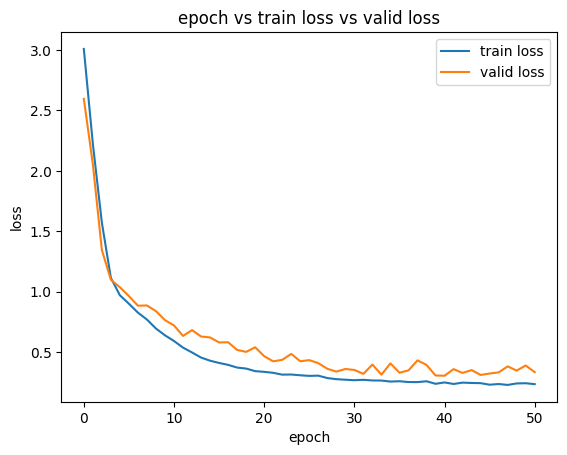

plot done

=== V2 training m=0.65 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_hdfs_baseline/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


100%|██████████| 4855/4855 [00:00<00:00, 73843.38it/s]

Num of train seqs 4370
Num of valid seqs 485

Loading valid Dataset
Creating Dataloader


Building BERT model
Creating BERT Trainer
Total Parameters: 2120213
Training Start


start calculate center


  0%|          | 0/136 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/15 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/d

...

Epoch: 38 | phase: valid, loss=0.35060126384099327
logkey loss: 0.33963226874669394, hyper loss: 0.10968998670578003

Log saved


start calculate center


  0%|          | 0/136 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/15 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/d

Epoch: 39 | phase: train, loss=0.28416643582065315
logkey loss: 0.2733469086096567, hyper loss: 0.1081952804370838



/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 39 | phase: valid, loss=0.40750577648480735
logkey loss: 0.397112629810969, hyper loss: 0.10393151094516119

Log saved
Early stopping


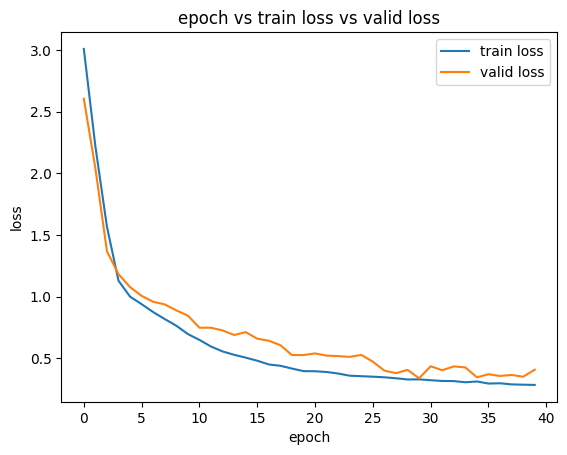

plot done

=== V2 training m=0.75 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_hdfs_baseline/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


100%|██████████| 4855/4855 [00:00<00:00, 66332.93it/s]

Num of train seqs 4370
Num of valid seqs 485

Loading valid Dataset
Creating Dataloader


Building BERT model
Creating BERT Trainer
Total Parameters: 2120213
Training Start


start calculate center


  0%|          | 0/136 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/15 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/d

...

Epoch: 49 | phase: valid, loss=0.38457239071528115
logkey loss: 0.3770682503779729, hyper loss: 0.07504143665234247

Log saved


start calculate center


  0%|          | 0/136 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/15 [00:00<?, ?it/s]/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/d

Epoch: 50 | phase: train, loss=0.2981725120369126
logkey loss: 0.29056301943081264, hyper loss: 0.07609493778470684



/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_hdfs_baseline/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 50 | phase: valid, loss=0.4057866563399633
logkey loss: 0.39842641552289326, hyper loss: 0.07360234210888544

Log saved
Early stopping


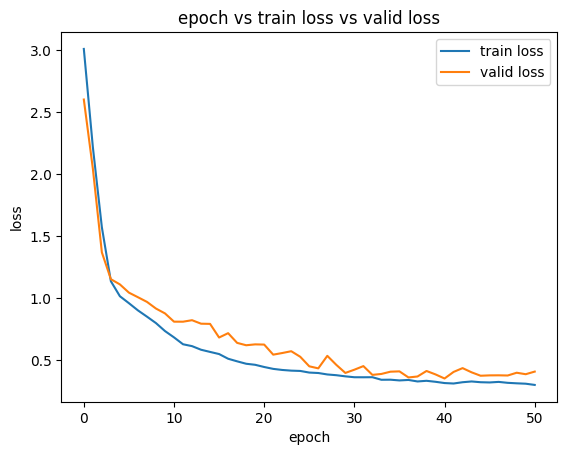

plot done
V2 models trained: [0.5, 0.65, 0.75]


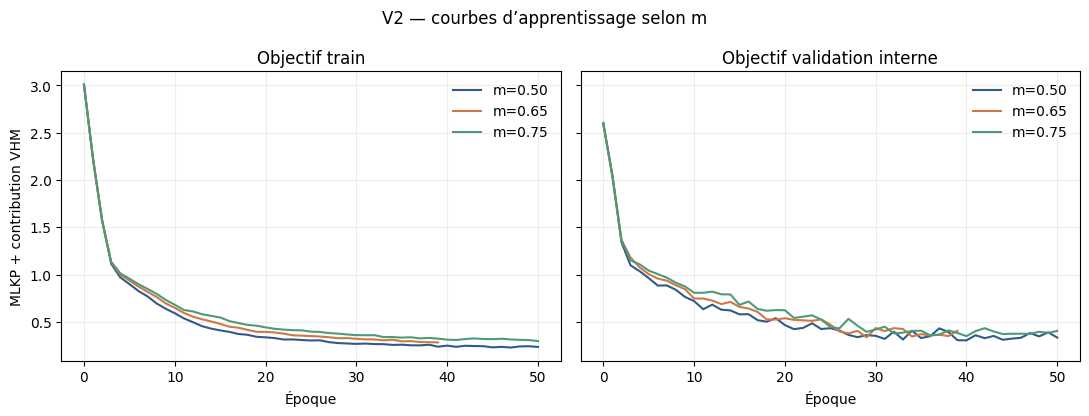

In [21]:
import random
import subprocess
from bert_pytorch import Trainer
from bert_pytorch.dataset.utils import seed_everything

V2_MASK_GRID = [0.50, 0.65, 0.75]
V2_MODELS = {}
V2_OPTIONS = {}

# Reassert the two minimal NumPy-2 compatibility conversions in the official repo.
ragged_patches = {
    REPO_DIR / "bert_pytorch" / "dataset" / "sample.py": [
        ("np.array(logkey_seq_pairs)", "np.array(logkey_seq_pairs, dtype=object)"),
        ("np.array(time_seq_pairs)", "np.array(time_seq_pairs, dtype=object)"),
    ],
    REPO_DIR / "bert_pytorch" / "predict_log.py": [
        ("np.array(log_seqs)", "np.array(log_seqs, dtype=object)"),
        ("np.array(tim_seqs)", "np.array(tim_seqs, dtype=object)"),
    ],
}
for source_path, pairs in ragged_patches.items():
    content = source_path.read_text(encoding="utf-8")
    for old_expr, new_expr in pairs:
        if new_expr not in content and old_expr in content:
            content = content.replace(old_expr, new_expr)
    source_path.write_text(content, encoding="utf-8")

# Vocabulary is derived only from the fixed normal training partition.
subprocess.run([sys.executable, "logbert.py", "vocab"], cwd=REPO_HDFS, check=True)
from bert_pytorch.dataset import WordVocab
v2_vocab_path = OUTPUT_DIR / "vocab.pkl"
v2_vocab = WordVocab.load_vocab(str(v2_vocab_path))

spec_v2 = importlib.util.spec_from_file_location("hdfs_logbert_v2_config", REPO_HDFS / "logbert.py")
cfg_v2 = importlib.util.module_from_spec(spec_v2)
spec_v2.loader.exec_module(cfg_v2)

for mask_ratio in V2_MASK_GRID:
    tag = f"m{mask_ratio:.2f}".replace(".", "p")
    model_dir = OUTPUT_DIR / "v2" / tag
    model_dir.mkdir(parents=True, exist_ok=True)
    options = cfg_v2.options.copy()
    options.update({
        "device": "cuda" if torch.cuda.is_available() else "cpu",
        "output_dir": str(OUTPUT_DIR) + "/",
        "model_dir": str(model_dir) + "/",
        "model_path": str(model_dir / "best_bert.pth"),
        "vocab_path": str(v2_vocab_path),
        "scale_path": str(model_dir / "scale.pkl"),
        "mask_ratio": mask_ratio,
        "num_workers": 2,
        "on_memory": True,
    })
    # Pair initialization/training seeds across the m ablation.
    seed_everything(seed=1234)
    print(f"\n=== V2 training m={mask_ratio:.2f} ===")
    trainer = Trainer(options)
    trainer.train()
    checkpoint = Path(options["model_path"])
    if not checkpoint.exists():
        raise FileNotFoundError(f"V2 checkpoint missing for m={mask_ratio}: {checkpoint}")
    try:
        candidate_model = torch.load(str(checkpoint), map_location=options["device"], weights_only=False)
    except TypeError:
        candidate_model = torch.load(str(checkpoint), map_location=options["device"])
    candidate_model.to(options["device"]); candidate_model.eval()
    V2_MODELS[mask_ratio] = candidate_model
    V2_OPTIONS[mask_ratio] = options
    del trainer

print("V2 models trained:", list(V2_MODELS))

# Compare the official total objective learning curves for each masking ratio.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
colors = ["#315A8A", "#D07845", "#4E9A75", "#A66BBE"]
for index, mask_ratio in enumerate(V2_MASK_GRID):
    tag = f"m{mask_ratio:.2f}".replace(".", "p")
    log_dir = OUTPUT_DIR / "v2" / tag
    train_log = pd.read_csv(log_dir / "train_log2.csv")
    valid_log = pd.read_csv(log_dir / "valid_log2.csv")
    axes[0].plot(train_log.epoch, train_log.loss, color=colors[index % len(colors)],
                 label=f"m={mask_ratio:.2f}")
    axes[1].plot(valid_log.epoch, valid_log.loss, color=colors[index % len(colors)],
                 label=f"m={mask_ratio:.2f}")
axes[0].set_title("Objectif train"); axes[1].set_title("Objectif validation interne")
for ax in axes:
    ax.set_xlabel("Époque"); ax.grid(alpha=.22); ax.legend(frameon=False)
axes[0].set_ylabel("MLKP + contribution VHM")
fig.suptitle("V2 — courbes d’apprentissage selon m")
fig.tight_layout(); fig.savefig(WORK_DIR / "logbert_v2_loss_curves.png", dpi=220, bbox_inches="tight"); plt.show()

## V2 — Validation-only selection de `m`, `g` et `r`

Chaque modèle est évalué avec le même ratio `m` que celui utilisé pendant son entraînement. Pour chaque modèle, `g` et `r` sont sélectionnés sur validation à la prévalence HDFS de référence. Le test n’est utilisé qu’après le choix du triplet.


55336it [00:00, 69432.65it/s]


val_normal size: 55336


2139it [00:00, 50744.44it/s]

val_abnormal size: 2139



55336it [00:00, 69115.07it/s]

...

498032it [00:06, 72354.96it/s]


test_normal size: 498032
test_normal: 1,339,897 masked positions
test_normal: 2,410,869 masked positions
test_normal: 3,331,001 masked positions
test_normal: 4,243,893 masked positions
test_normal: 5,156,504 masked positions
test_normal: 6,068,297 masked positions
test_normal: 6,800,036 masked positions


8508it [00:00, 58750.35it/s]

test_abnormal size: 8508


V2 locked test result:
     m  g      r  Precision  Recall     F1    FPR   TP   FP   FN     TN  ROC_AUC  PR_AUC  test_prevalence                           Precision_CI95                              Recall_CI95
0.7500  8 0.0400     0.8267  0.8362 0.8314 0.0030 7114 1491 1394 496541   0.9235  0.7051           0.0168 [0.8185864837626294, 0.8345792211579349] [0.8281378745503535, 0.8438671231546321]
                  version  Precision  Recall     F1  ROC_AUC  PR_AUC
     Article LogBERT HDFS     0.8702  0.7810 0.8232      NaN     NaN
V1 official m=.65,g=6,r=0     0.6278  0.8017 0.7042   0.8979  0.6338
     V2 m=0.75,g=8,r=0.04     0.8267  0.8362 0.8314   0.9235  0.7051


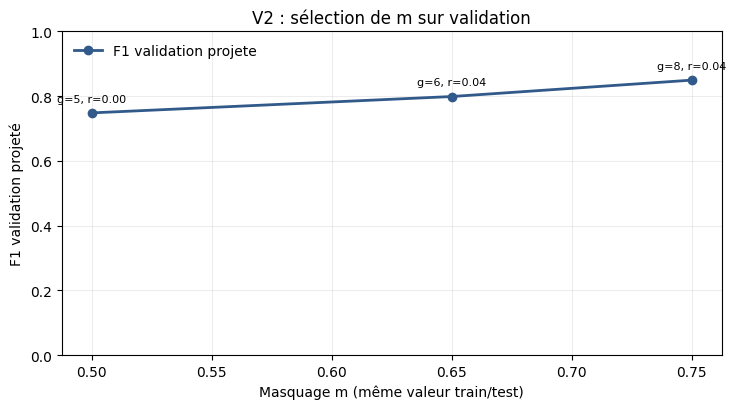

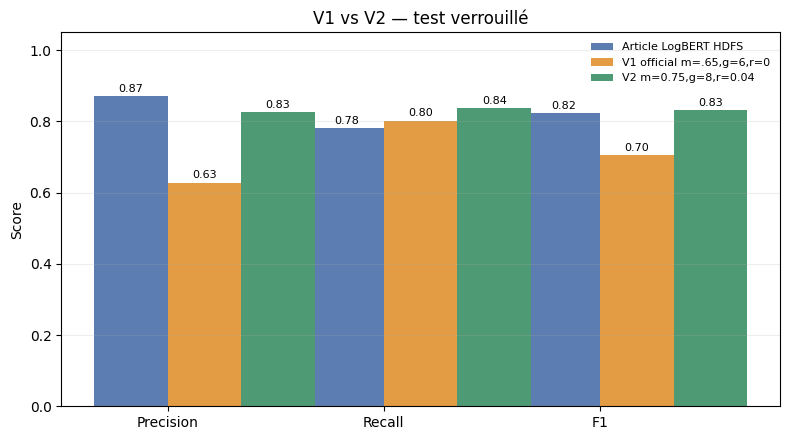

V2 results saved: /kaggle/working/.logbert_hdfs_baseline/logbert_hdfs_v2_results.json


In [30]:
from bert_pytorch.dataset import LogDataset
from bert_pytorch import Predictor
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

V2_G_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
V2_G_GRID = [g for g in V2_G_GRID if g <= len(v2_vocab)]
V2_R_GRID = np.arange(0.0, 0.801, 0.01)
V2_TARGET_PREVALENCE = 10647 / (553366 + 10647)

def v2_scores_by_g(model, options, filename, seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    predictor_v2 = Predictor(options)
    log_seqs, time_seqs = predictor_v2.generate_test(
        options["output_dir"], filename, predictor_v2.window_size,
        predictor_v2.adaptive_window, predictor_v2.seq_len, None, predictor_v2.min_len,
    )
    dataset = LogDataset(log_seqs, time_seqs, v2_vocab, seq_len=predictor_v2.seq_len,
                         corpus_lines=predictor_v2.corpus_lines, on_memory=False,
                         predict_mode=True, mask_ratio=options["mask_ratio"])
    loader = DataLoader(dataset, batch_size=predictor_v2.batch_size,
                        num_workers=predictor_v2.num_workers, collate_fn=dataset.collate_fn)
    errors = {g: [] for g in V2_G_GRID}
    n_masked_by_sequence = []
    for batch_index, batch in enumerate(loader):
        batch = {key: value.to(options["device"]) for key, value in batch.items()}
        with torch.no_grad():
            logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
        labels = batch["bert_label"]
        for i in range(len(labels)):
            mask = labels[i] > 0
            target = labels[i][mask]
            masked_logits = logits[i][mask]
            n_masked = len(target)
            n_masked_by_sequence.append(n_masked)
            if n_masked:
                top_ids = torch.topk(masked_logits, k=max(V2_G_GRID), dim=-1).indices
                matches = top_ids == target.unsqueeze(1)
                for g in V2_G_GRID:
                    errors[g].append(int((~matches[:, :g].any(dim=1)).sum().item()))
            else:
                for g in V2_G_GRID:
                    errors[g].append(0)
        if batch_index and batch_index % 2000 == 0:
            print(f"{filename}: {sum(n_masked_by_sequence):,} masked positions")
    denominator = np.maximum(np.asarray(n_masked_by_sequence, dtype=float), 1)
    return {g: np.asarray(errors[g], dtype=float) / denominator for g in V2_G_GRID}


def v2_threshold_metrics(y, score, r, prior=V2_TARGET_PREVALENCE):
    pred = (score > r).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    recall = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    precision_target = prior * recall / max(prior * recall + (1-prior) * fpr, 1e-12)
    f1_target = 2 * precision_target * recall / max(precision_target + recall, 1e-12)
    return {"Precision_target": precision_target, "Recall": recall, "F1_target": f1_target,
            "FPR": fpr, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}


y_val_v2 = np.r_[np.zeros(len(val_normal), dtype=int), np.ones(len(val_anomaly), dtype=int)]
y_test_v2 = np.r_[np.zeros(len(test_normal), dtype=int), np.ones(len(test_anomaly), dtype=int)]
V2_VALIDATION_SCORES = {}
v2_search_rows = []
for m, candidate_model in V2_MODELS.items():
    opts = V2_OPTIONS[m]
    val_n = v2_scores_by_g(candidate_model, opts, "val_normal", 1234)
    val_a = v2_scores_by_g(candidate_model, opts, "val_abnormal", 1235)
    V2_VALIDATION_SCORES[m] = (val_n, val_a)
    for g in V2_G_GRID:
        score = np.r_[val_n[g], val_a[g]]
        for r in V2_R_GRID:
            row = v2_threshold_metrics(y_val_v2, score, r)
            v2_search_rows.append({"m": m, "g": g, "r": float(r), **row})

v2_search = pd.DataFrame(v2_search_rows)
v2_best = v2_search.sort_values(["F1_target", "Recall", "Precision_target"], ascending=False).iloc[0]
V2_BEST_M, V2_BEST_G, V2_BEST_R = float(v2_best.m), int(v2_best.g), float(v2_best.r)
print("V2 selected on validation:", {"m": V2_BEST_M, "g": V2_BEST_G, "r": V2_BEST_R,
                                       "validation_F1_target": float(v2_best.F1_target),
                                       "validation_precision_target": float(v2_best.Precision_target),
                                       "validation_recall": float(v2_best.Recall)})

# Only the selected V2 model is now scored on test.
best_model = V2_MODELS[V2_BEST_M]
best_options = V2_OPTIONS[V2_BEST_M]
test_n = v2_scores_by_g(best_model, best_options, "test_normal", 1236)
test_a = v2_scores_by_g(best_model, best_options, "test_abnormal", 1237)
v2_test_scores = np.r_[test_n[V2_BEST_G], test_a[V2_BEST_G]]
v2_pred = (v2_test_scores > V2_BEST_R).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test_v2, v2_pred, labels=[0,1]).ravel()
v2_test_result = {
    "m": V2_BEST_M, "g": V2_BEST_G, "r": V2_BEST_R,
    "Precision": precision_score(y_test_v2, v2_pred, zero_division=0),
    "Recall": recall_score(y_test_v2, v2_pred, zero_division=0),
    "F1": f1_score(y_test_v2, v2_pred, zero_division=0),
    "FPR": fp / max(tn+fp,1), "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    "ROC_AUC": roc_auc_score(y_test_v2, v2_test_scores),
    "PR_AUC": average_precision_score(y_test_v2, v2_test_scores),
    "test_prevalence": float(y_test_v2.mean()),
}
from scipy.stats import norm
def v2_wilson(successes, total, confidence=0.95):
    if total <= 0: return [float("nan"), float("nan")]
    z=norm.ppf(.5+confidence/2); p=successes/total; den=1+z*z/total
    center=(p+z*z/(2*total))/den
    half=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/den
    return [max(0.,center-half), min(1.,center+half)]
v2_test_result["Precision_CI95"] = v2_wilson(tp,tp+fp)
v2_test_result["Recall_CI95"] = v2_wilson(tp,tp+fn)
print("V2 locked test result:")
print(pd.DataFrame([v2_test_result]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Compare V1 from the completed baseline and V2 selected without test labels.
v1_file = WORK_DIR / "logbert_hdfs_full_baseline.json"
if v1_file.exists():
    v1_protocol = json.loads(v1_file.read_text())["protocol"]
    v1_comparison = {"version": "V1 official m=.65,g=6,r=0", **{key: v1_protocol[key] for key in ["Precision","Recall","F1","ROC_AUC","PR_AUC"]}}
else:
    # Frozen metrics from the V1 full-HDFS run if its working directory was cleaned.
    v1_comparison = {"version": "V1 official m=.65,g=6,r=0", "Precision": .6278, "Recall": .8017,
                     "F1": .7042, "ROC_AUC": .8979, "PR_AUC": .6338}
v2_comparison = {"version": f"V2 m={V2_BEST_M:.2f},g={V2_BEST_G},r={V2_BEST_R:.2f}", **v2_test_result}
paper_comparison = {"version": "Article LogBERT HDFS", "Precision": .8702, "Recall": .7810, "F1": .8232, "ROC_AUC": np.nan, "PR_AUC": np.nan}
comparison_v1_v2 = pd.DataFrame([paper_comparison, v1_comparison, v2_comparison])
print(comparison_v1_v2[["version", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# V2 clean plots: validation config quality and locked-test V1/V2 comparison.
best_by_m = v2_search.loc[v2_search.groupby("m").F1_target.idxmax()].sort_values("m")
fig, ax = plt.subplots(figsize=(7.5,4.2))
ax.plot(best_by_m.m, best_by_m.F1_target, "o-", color="#315A8A", linewidth=2, label="F1 validation projete")
ax.legend(frameon=False)
for row in best_by_m.itertuples():
    ax.annotate(f"g={row.g}, r={row.r:.2f}", (row.m,row.F1_target), xytext=(0,8), textcoords="offset points", ha="center", fontsize=8)
ax.set_xlabel("Masquage m (même valeur train/test)"); ax.set_ylabel("F1 validation projeté")
ax.set_title("V2 : sélection de m sur validation"); ax.set_ylim(0,1); ax.grid(alpha=.22)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4.5))
metric_names=["Precision","Recall","F1"]
x=np.arange(3); width=.34
for idx,row in comparison_v1_v2.iterrows():
    bars=ax.bar(x+(idx-.5)*width,[row[k] for k in metric_names],width,label=row.version,
                color=["#5B7DB1","#E39C43","#4E9A75"][idx % 3])
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.012,f"{bar.get_height():.2f}",ha="center",fontsize=8)
ax.set_xticks(x,metric_names); ax.set_ylim(0,1.05); ax.set_ylabel("Score")
ax.set_title("V1 vs V2 — test verrouillé"); ax.legend(frameon=False,fontsize=8); ax.grid(axis="y",alpha=.22)
fig.tight_layout(); plt.show()

# Persist V2 metrics/validation sweep for independent audit.
v2_result_path = WORK_DIR / "logbert_hdfs_v2_results.json"
v2_result_path.write_text(json.dumps({"selected": v2_test_result,
                                      "validation_search": v2_search.to_dict("records"),
                                      "v1_comparison": v1_comparison, "paper_reference": paper_comparison,
                                      "repo_commit": REPO_COMMIT}, indent=2,
                                     default=lambda value: value.item() if hasattr(value,"item") else str(value)))
print("V2 results saved:", v2_result_path)


## V2 — Rapport détaillé et figures de diagnostic

Les métriques sont calculées au seuil gelé depuis la validation. La courbe du test selon `r` est uniquement descriptive : elle ne sert pas à modifier le réglage sélectionné.


Matrice de confusion [lignes=réel, colonnes=prédit]:
                 Normal prédit  Anomalie prédite
Normal réel             496541              1491
Anomalie réelle           1394              7114

Accuracy=99.430% | Balanced accuracy=91.658% | Specificity=99.701%
              precision    recall  f1-score   support

      Normal     0.9972    0.9970    0.9971    498032
    Anomalie     0.8267    0.8362    0.8314      8508

    accuracy                         0.9943    506540
   macro avg     0.9120    0.9166    0.9143    506540
weighted avg     0.9943    0.9943    0.9943    506540



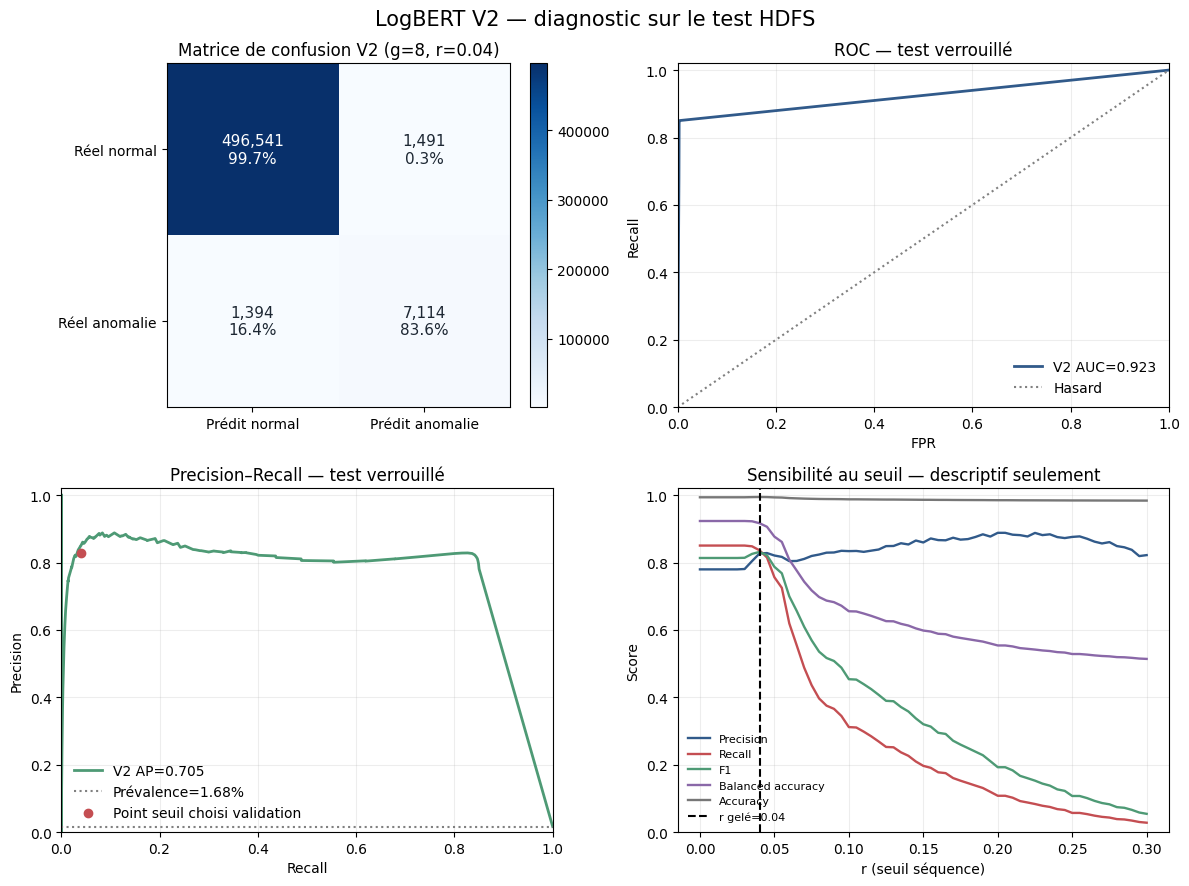

Figure saved: /kaggle/working/.logbert_hdfs_baseline/logbert_v2_test_diagnostics.png


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, accuracy_score, balanced_accuracy_score, classification_report

v2_test_prediction = (v2_test_scores > V2_BEST_R).astype(int)
v2_cm = confusion_matrix(y_test_v2, v2_test_prediction, labels=[0,1])
v2_tn, v2_fp, v2_fn, v2_tp = v2_cm.ravel()
v2_specificity = v2_tn / max(v2_tn + v2_fp, 1)
v2_accuracy = accuracy_score(y_test_v2, v2_test_prediction)
v2_balanced_accuracy = balanced_accuracy_score(y_test_v2, v2_test_prediction)

print("Matrice de confusion [lignes=réel, colonnes=prédit]:")
print(pd.DataFrame(v2_cm, index=["Normal réel", "Anomalie réelle"],
                   columns=["Normal prédit", "Anomalie prédite"]).to_string())
print(f"\nAccuracy={v2_accuracy:.3%} | Balanced accuracy={v2_balanced_accuracy:.3%} | Specificity={v2_specificity:.3%}")
print(classification_report(y_test_v2, v2_test_prediction, target_names=["Normal", "Anomalie"], digits=4, zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Confusion matrix with counts and row-normalized rates.
ax = axes[0,0]
row_totals = np.maximum(v2_cm.sum(axis=1, keepdims=True), 1)
row_pct = v2_cm / row_totals
image = ax.imshow(v2_cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{v2_cm[i,j]:,}\n{row_pct[i,j]:.1%}", ha="center", va="center",
                fontsize=11, color="white" if v2_cm[i,j] > v2_cm.max()*.55 else "#1d2733")
ax.set_xticks([0,1], ["Prédit normal", "Prédit anomalie"])
ax.set_yticks([0,1], ["Réel normal", "Réel anomalie"])
ax.set_title(f"Matrice de confusion V2 (g={V2_BEST_G}, r={V2_BEST_R:.2f})")
fig.colorbar(image, ax=ax, fraction=.046, pad=.04)

# ROC.
fpr_curve, tpr_curve, _ = roc_curve(y_test_v2, v2_test_scores)
ax = axes[0,1]
ax.plot(fpr_curve, tpr_curve, color="#315A8A", linewidth=2,
        label=f"V2 AUC={auc(fpr_curve,tpr_curve):.3f}")
ax.plot([0,1],[0,1], color="grey", linestyle=":", label="Hasard")
ax.set(xlabel="FPR", ylabel="Recall", title="ROC — test verrouillé", xlim=(0,1), ylim=(0,1.02))
ax.legend(frameon=False); ax.grid(alpha=.22)

# Precision-recall.
pr_precision, pr_recall, _ = precision_recall_curve(y_test_v2, v2_test_scores)
ax = axes[1,0]
ax.plot(pr_recall, pr_precision, color="#4E9A75", linewidth=2,
        label=f"V2 AP={average_precision_score(y_test_v2,v2_test_scores):.3f}")
ax.axhline(float(y_test_v2.mean()), color="grey", linestyle=":",
           label=f"Prévalence={y_test_v2.mean():.2%}")
ax.scatter([V2_BEST_R], [v2_test_result["Precision"]], color="#C44E52", zorder=3,
           label="Point seuil choisi validation")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall — test verrouillé", xlim=(0,1), ylim=(0,1.02))
ax.legend(frameon=False); ax.grid(alpha=.22)

# Threshold sensitivity on test; diagnostic only, selected threshold stays fixed from validation.
r_curve = np.arange(0, .301, .005)
curve_rows=[]
for r_value in r_curve:
    pred=(v2_test_scores > r_value).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test_v2,pred,labels=[0,1]).ravel()
    precision=tp/max(tp+fp,1); recall=tp/max(tp+fn,1)
    specificity=tn/max(tn+fp,1)
    curve_rows.append({"r":r_value,"Precision":precision,"Recall":recall,
                       "F1":2*precision*recall/max(precision+recall,1e-12),
                       "Accuracy":(tp+tn)/len(y_test_v2),
                       "Balanced accuracy":(recall+specificity)/2})
curve_df=pd.DataFrame(curve_rows)
ax=axes[1,1]
for metric,color in [("Precision","#315A8A"),("Recall","#C44E52"),("F1","#4E9A75"),
                     ("Balanced accuracy","#8A68A8"),("Accuracy","#777777")]:
    ax.plot(curve_df.r,curve_df[metric],label=metric,color=color,linewidth=1.7)
ax.axvline(V2_BEST_R,color="black",linestyle="--",label=f"r gelé={V2_BEST_R:.2f}")
ax.set(xlabel="r (seuil séquence)",ylabel="Score",title="Sensibilité au seuil — descriptif seulement",ylim=(0,1.02))
ax.legend(frameon=False,fontsize=8); ax.grid(alpha=.22)

fig.suptitle("LogBERT V2 — diagnostic sur le test HDFS", fontsize=15)
fig.tight_layout()
figure_path=WORK_DIR / "logbert_v2_test_diagnostics.png"
fig.savefig(figure_path,dpi=220,bbox_inches="tight")
plt.show()
print("Figure saved:",figure_path)


## Export du meilleur modèle et API d’inférence AIOps

Cette cellule exporte le checkpoint, le vocabulaire, le mapping Drain et une fonction Python de scoring/evidence pour le SLM. L’API reçoit les séquences d’EventId numériques déjà produites par Drain; elle ne prend pas de lignes brutes. Elle effectue un smoke test sur deux séquences de validation, sans toucher au seuil ni aux métriques test.


In [32]:
import os, json, shutil, zipfile, textwrap
from pathlib import Path

ARTIFACT_DIR = Path("/kaggle/working/logbert_v2_best")
if ARTIFACT_DIR.exists():
    shutil.rmtree(ARTIFACT_DIR)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

best_options = V2_OPTIONS[V2_BEST_M]
best_model = V2_MODELS[V2_BEST_M]
best_checkpoint = Path(best_options["model_path"])
if not best_checkpoint.exists():
    raise FileNotFoundError(best_checkpoint)

# Copy the exact official model checkpoint and training vocabulary.
shutil.copy2(best_checkpoint, ARTIFACT_DIR / "best_bert.pth")
shutil.copy2(v2_vocab_path, ARTIFACT_DIR / "vocab.pkl")
templates_csv = OUTPUT_DIR / "HDFS.log_templates.csv"
template_map_json = OUTPUT_DIR / "hdfs_log_templates.json"
if templates_csv.exists():
    shutil.copy2(templates_csv, ARTIFACT_DIR / "HDFS.log_templates.csv")
if template_map_json.exists():
    shutil.copy2(template_map_json, ARTIFACT_DIR / "hdfs_log_templates.json")

# Event hash -> integer key mapping used when building the training sequences.
template_df = pd.read_csv(templates_csv)
hash_to_template = dict(zip(template_df.EventId.astype(str), template_df.EventTemplate.astype(str)))
hash_to_id = json.loads(template_map_json.read_text())
id_to_template = {str(int(event_id)): hash_to_template[str(event_hash)]
                  for event_hash, event_id in hash_to_id.items()
                  if str(event_hash) in hash_to_template}

manifest = {
    "model": "Official LogBERT HDFS implementation",
    "repository": "https://github.com/HelenGuohx/LogBERT",
    "repository_commit": REPO_COMMIT,
    "dataset": "LogHub HDFS_v1 full",
    "artifact_type": "serialized full PyTorch model plus WordVocab pickle",
    "mask_ratio_m": float(V2_BEST_M),
    "top_g": int(V2_BEST_G),
    "sequence_threshold_r": float(V2_BEST_R),
    "sequence_length": int(best_options["seq_len"]),
    "adaptive_window": bool(best_options["adaptive_window"]),
    "minimum_sequence_length": int(best_options["min_len"]),
    "prediction_rule": "anomaly iff undetected masked keys > masked keys * r",
    "input_contract": "list of per-session integer LogPai EventId values after the bundled Drain mapping",
    "id_to_template": id_to_template,
    "event_hash_to_id": {str(k): int(v) for k, v in hash_to_id.items()},
    "test_metrics": v2_test_result,
}
(ARTIFACT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=lambda x: x.item() if hasattr(x,"item") else str(x)))
torch.save(best_model.state_dict(), ARTIFACT_DIR / "best_bert_state_dict.pth")

inference_source = r"""import json
from pathlib import Path
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from bert_pytorch.dataset import WordVocab, LogDataset


def load_logbert_bundle(artifact_dir, repo_commit=None, device=None):
    # Load after adding the matching official LogBERT repo to sys.path.
    from bert_pytorch import Predictor
    artifact_dir = Path(artifact_dir)
    manifest = json.loads((artifact_dir / "manifest.json").read_text())
    if repo_commit is not None and repo_commit != manifest["repository_commit"]:
        raise ValueError("LogBERT repository commit differs from exported artifact")
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    vocab = WordVocab.load_vocab(str(artifact_dir / "vocab.pkl"))
    try:
        model = torch.load(str(artifact_dir / "best_bert.pth"), map_location=device, weights_only=False)
    except TypeError:
        model = torch.load(str(artifact_dir / "best_bert.pth"), map_location=device)
    model.to(device); model.eval()
    return {"manifest": manifest, "vocab": vocab, "model": model, "device": device}


def encode_event_hashes(event_hashes, manifest):
    # Map Drain event hashes to training integer IDs; unseen hashes become OOV.
    mapping = manifest["event_hash_to_id"]
    return [mapping.get(str(event_hash), "<UNMAPPED_EVENT>") for event_hash in event_hashes]


def predict_event_sequences(event_sequences, bundle, session_ids=None, seed=2025, batch_size=64):
    # Input sequences are integer EventIds or strings from the bundled mapping.
    # Raw log lines must be parsed upstream with the compatible Drain mapping.
    manifest, vocab, model, device = (bundle[k] for k in ("manifest", "vocab", "model", "device"))
    ids = list(session_ids) if session_ids is not None else [str(i) for i in range(len(event_sequences))]
    if len(ids) != len(event_sequences):
        raise ValueError("session_ids and event_sequences length mismatch")
    minimum = int(manifest["minimum_sequence_length"])
    max_len = int(manifest["sequence_length"])
    eligible = []
    results = [None] * len(event_sequences)
    for idx, sequence in enumerate(event_sequences):
        sequence = list(map(str, sequence))[:max_len]
        if len(sequence) < minimum:
            results[idx] = {"session_id": ids[idx], "scored": False,
                            "reason": f"sequence shorter than min_len={minimum}"}
        else:
            eligible.append((idx, sequence))
    if not eligible:
        return results

    mask_ratio, top_g, threshold = (float(manifest["mask_ratio_m"]),
                                    int(manifest["top_g"]),
                                    float(manifest["sequence_threshold_r"]))
    sequences = [seq for _, seq in eligible]
    times = [[0.0] * len(seq) for seq in sequences]
    dataset = LogDataset(sequences, times, vocab, seq_len=max_len,
                         corpus_lines=len(sequences), on_memory=True,
                         predict_mode=True, mask_ratio=mask_ratio)
    generator = torch.Generator(); generator.manual_seed(seed)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=0, collate_fn=dataset.collate_fn, generator=generator)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    id_to_template = manifest.get("id_to_template", {})

    out_idx = 0
    for batch in loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        with torch.no_grad():
            logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
        labels = batch["bert_label"]
        for local_i in range(len(labels)):
            mask = labels[local_i] > 0
            targets = labels[local_i][mask]
            positions = torch.where(mask)[0]
            masked_logits = logits[local_i][mask]
            evidence = []
            if len(targets):
                candidates = torch.topk(masked_logits, k=top_g, dim=-1).indices
                errors = ~(candidates == targets.unsqueeze(1)).any(dim=1)
                error_count = int(errors.sum().item())
                for j in torch.where(errors)[0].tolist():
                    # LogDataset prepends SOS, so subtract one to recover event position.
                    event_pos = int(positions[j].item()) - 1
                    if event_pos < 0:
                        continue
                    observed = sequences[out_idx][event_pos]
                    candidate_tokens = [vocab.itos[int(t)] for t in candidates[j].tolist()]
                    evidence.append({
                        "position": event_pos,
                        "observed_event_id": observed,
                        "observed_template": id_to_template.get(str(observed), "unknown/unmapped event template"),
                        "top_g_candidate_ids": candidate_tokens,
                        "top_g_candidate_templates": [id_to_template.get(str(t), t) for t in candidate_tokens],
                    })
                masked_count = len(targets)
                score = error_count / max(masked_count, 1)
            else:
                error_count = masked_count = 0
                score = 0.0
            original_index, _ = eligible[out_idx]
            results[original_index] = {
                "session_id": ids[original_index],
                "scored": True,
                "anomaly": bool(score > threshold),
                "anomaly_score": float(score),
                "m": mask_ratio, "g": top_g, "r": threshold,
                "masked_tokens": int(masked_count),
                "undetected_tokens": int(error_count),
                "evidence": evidence[:20],
            }
            out_idx += 1
    return results
"""
(ARTIFACT_DIR / "inference.py").write_text(inference_source, encoding="utf-8")
(ARTIFACT_DIR / "README_inference.txt").write_text(
    "V2 best LogBERT inference artifact. Input is a per-session list of integer LogPai EventIds from the included official Drain mapping. "
    "Add the official LogBERT repository at the commit in manifest.json to PYTHONPATH before loading the serialized model. "
    "The inference function returns anomaly decision, score, and top-g masked-key evidence for downstream SLM explanation.\\n",
    encoding="utf-8",
)

bundle_zip = shutil.make_archive("/kaggle/working/logbert_v2_best", "zip", ARTIFACT_DIR)
print("Artifact directory:", ARTIFACT_DIR)
print("Downloadable bundle:", bundle_zip)
print("Files:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

# Smoke test on validation samples only; it does not change thresholds or test metrics.
# Load the just-exported module by its file path (the artifact directory is not
# necessarily on sys.path in Kaggle).
sys.path.insert(0, str(REPO_DIR))
inference_spec = importlib.util.spec_from_file_location(
    "logbert_v2_inference", ARTIFACT_DIR / "inference.py"
)
inference_module = importlib.util.module_from_spec(inference_spec)
inference_spec.loader.exec_module(inference_module)
load_logbert_bundle = inference_module.load_logbert_bundle
predict_event_sequences = inference_module.predict_event_sequences
bundle = load_logbert_bundle(ARTIFACT_DIR, repo_commit=REPO_COMMIT)
smoke = predict_event_sequences([val_normal.events.iloc[0], val_anomaly.events.iloc[0]],
                                bundle, session_ids=["smoke-normal", "smoke-anomaly"], seed=SEED)
print("Inference smoke test:")
print(json.dumps(smoke, ensure_ascii=False, indent=2)[:4000])


Artifact directory: /kaggle/working/logbert_v2_best
Downloadable bundle: /kaggle/working/logbert_v2_best.zip
Files: ['HDFS.log_templates.csv', 'README_inference.txt', 'best_bert.pth', 'best_bert_state_dict.pth', 'hdfs_log_templates.json', 'inference.py', 'manifest.json', 'vocab.pkl']
Inference smoke test:
[
  {
    "session_id": "smoke-normal",
    "scored": true,
    "anomaly": false,
    "anomaly_score": 0.0,
    "m": 0.75,
    "g": 8,
    "r": 0.04,
    "masked_tokens": 15,
    "undetected_tokens": 0,
    "evidence": []
  },
  {
    "session_id": "smoke-anomaly",
    "scored": true,
    "anomaly": true,
    "anomaly_score": 0.05555555555555555,
    "m": 0.75,
    "g": 8,
    "r": 0.04,
    "masked_tokens": 18,
    "undetected_tokens": 1,
    "evidence": [
      {
        "position": 19,
        "observed_event_id": "15",
        "observed_template": "Unexpected error trying to delete block blk_<*>. BlockInfo not found in volumeMap.",
        "top_g_candidate_ids": [
          "5",
 

## Analyse causale SLM Qwen pour l'ingenieur

LogBERT decide **anomalie / normal** et fournit les preuves (score, cles masquees hors top-g, templates Drain).
Qwen **n'annule jamais** cette decision : il la traduit en explication operationnelle, avec chaine causale **probable**, incertitudes explicites et actions de verification.

Regles imposees au SLM :
- ne citer que des EventId presents dans le dossier de preuves ;
- distinguer fait observe / hypothese probable / information manquante ;
- ne jamais affirmer une cause racine certaine sans preuve suffisante ;
- proposer des verifications, pas des executions automatiques.



In [ ]:
# Analyse causale Qwen (retro-ingenierie assistee, pas de re-decision)
import json, re, textwrap
from pathlib import Path
import torch

SLM_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"  # changeable: ex. "Qwen/Qwen2.5-3B-Instruct" si VRAM OK
N_TP_CASES, N_FP_CASES = 4, 2
SLM_SEED = 2025
SLM_MAX_NEW_TOKENS = 380

# 1. Recuperer le bundle V2 (recharge si kernel relance)
if 'bundle' not in globals():
    import sys, importlib.util
    sys.path.insert(0, str(REPO_DIR))
    _spec = importlib.util.spec_from_file_location("logbert_v2_inference", ARTIFACT_DIR / "inference.py")
    _mod = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_mod)
    bundle = _mod.load_logbert_bundle(ARTIFACT_DIR, repo_commit=REPO_COMMIT)
    predict_event_sequences = _mod.predict_event_sequences

# 2. Choisir des cas test : TP puis FP, scores les plus forts d'abord
test_ids = list(test_normal.BlockId.astype(str)) + list(test_anomaly.BlockId.astype(str))
test_labels = [0]*len(test_normal) + [1]*len(test_anomaly)
order = sorted(range(len(y_test_v2)), key=lambda i: float(v2_test_scores[i]), reverse=True)
tp_idx = [i for i in order if y_test_v2[i]==1 and (v2_test_scores[i] > V2_BEST_R)][:N_TP_CASES]
fp_idx = [i for i in order if y_test_v2[i]==0 and (v2_test_scores[i] > V2_BEST_R)][:N_FP_CASES]
sel_idx = tp_idx + fp_idx
print(f"Cas selectionnes: {len(tp_idx)} TP + {len(fp_idx)} FP")
sel_sequences = [list(map(str, (test_normal.events.tolist()+test_anomaly.events.tolist())[i])) for i in sel_idx]
sel_ids = [test_ids[i] for i in sel_idx]
sel_true = [test_labels[i] for i in sel_idx]

dossiers = predict_event_sequences(sel_sequences, bundle, session_ids=sel_ids, seed=SLM_SEED)
for d, t in zip(dossiers, sel_true):
    d["vrai_label"] = int(t)

# 3. Prompt contraint : Qwen explique, ne re-decide pas
SYSTEM = ("Tu es un ingenieur SRE HDFS. LogBERT a deja classe la session comme anormale. "
 "Explique le dossier pour un ingenieur d'astreinte : ce que LogBERT a vu, la chaine causale la plus probable, "
 "ce qui reste incertain, et les verifications concretes. "
 "REGLES STRICTES : ne cite que des EventId du dossier ; ne confonds jamais hypothese et preuve ; "
 "si les preuves sont insuffisantes, baisse la confiance et demande des verifications. "
 "Reponds UNIQUEMENT en JSON valide avec les cles : resume_ingenieur, lecture_logbert, chaine_causale_probable, "
 "incertitudes, actions_recommandees (liste d'objets {action, pourquoi, priorite P1/P2/P3}), "
 "confiance (0-1), evenements_cites (liste d'EventId).")

def build_user(d):
    lines = [f"Session {d['session_id']} | vrai_label={d['vrai_label']} | score={d['anomaly_score']:.3f} "
             f"(m={d['m']}, g={d['g']}, r={d['r']}) | masques={d['masked_tokens']} non-predits={d['undetected_tokens']}"]
    for e in d["evidence"][:12]:
        lines.append(f"- pos {e['position']} : Event {e['observed_event_id']} = {e['observed_template']} "
                     f"| top-{d['g']} attendus : {e['top_g_candidate_ids']}")
    if not d["evidence"]:
        lines.append("(aucune position hors top-g detaillee dans les 20 premieres preuves)")
    lines.append("Explique ce dossier pour un ingenieur. JSON uniquement.")
    return "\n".join(lines)

from transformers import AutoTokenizer, AutoModelForCausalLM
tok = AutoTokenizer.from_pretrained(SLM_MODEL_ID, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    SLM_MODEL_ID, trust_remote_code=True,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto", low_cpu_mem_usage=True).eval()

def parse_json(text):
    m = re.search(r"\{.*\}", text, re.S)
    if not m: return None
    try: return json.loads(m.group(0))
    except Exception: return None

results = []
for d in dossiers:
    prompt = tok.apply_chat_template(
        [{"role":"system","content":SYSTEM},{"role":"user","content":build_user(d)}],
        tokenize=False, add_generation_prompt=True)
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=SLM_MAX_NEW_TOKENS, do_sample=False)
    raw = tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)
    parsed = parse_json(raw)
    observed = {str(e["observed_event_id"]) for e in d["evidence"]}
    cited = set(map(str, (parsed or {}).get("evenements_cites", [])))
    grounded = bool(cited) and cited.issubset(observed | {str(x) for seq in sel_sequences for x in seq})
    results.append({"session_id": d["session_id"], "vrai_label": d["vrai_label"],
        "score": d["anomaly_score"], "preuves_logbert": d["evidence"][:8],
        "slm": parsed, "raw": raw[:2000], "preuves_ancrees": grounded,
        "json_valide": parsed is not None})

# 4. Affichage lisible pour le rapport
for r in results:
    print("="*100)
    print(f"Session {r['session_id']} | vrai_label={r['vrai_label']} | score={r['score']:.3f} | JSON valide={r['json_valide']} | preuves ancrees={r['preuves_ancrees']}")
    s = r["slm"] or {}
    for k in ["resume_ingenieur","lecture_logbert","chaine_causale_probable","incertitudes","actions_recommandees","confiance"]:
        if k in s: print(f"- {k}: {s[k]}")
    if not r["slm"]: print("BRUT SLM:\n"+r["raw"][:1500])

out_path = WORK_DIR / "slm_qwen_causal.json"
out_path.write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
print("\nResultats SLM sauves:", out_path)
print(f"JSON valides: {sum(r['json_valide'] for r in results)}/{len(results)} | preuves ancrees: {sum(r['preuves_ancrees'] for r in results)}/{len(results)}")


### Lecture des sorties Qwen et limites

Metriques de qualite immediates : JSON valide, evenements cites presents dans le dossier LogBERT, confiance calibree, actions de verification (pas d'execution).
La justesse causale exige des incidents annotees par un expert : Qwen produit une hypothese explicable et actionnable, pas une preuve de cause racine.

